# Wildlife Multimodal Search Engine
### CSDS 305 — Project checkpoint: Database Insertion & Indexing

**Project status:** Data collection, preprocessing, embedding generation and vector indexing are completed. The search application is **not built yet**.

**Goal:** Build a semantic search system for six bird species using text, photographs, bird calls and short videos. This notebook summarizes the work completed on a Windows PC and includes an **optional live database demonstration** using the real generated embeddings.

> **Important:** The figures on the first sections are the results obtained on the Windows project (reported from the successfully executed scripts). They are a progress report, not a claim that the original data has been uploaded to Google Colab.


## What I can explain to the professor (about 1 minute)

> I collected data about six bird species, including texts, photographs, recordings and videos. Then I used Python to divide the text, audio and video into smaller parts and prepare the images. I generated embeddings with two pretrained models: CLIP for text, photos and video frames, and CLAP for bird sounds. Finally, I stored the vectors and metadata in ChromaDB using two separate HNSW indexes with cosine distance. The database contains 52 vectors and the basic retrieval tests worked. Next, I need to build the search interface and test its quality.

**Why two collections?** CLIP and CLAP are different vector spaces. Even though both output 512 numbers per vector, their embeddings cannot be compared directly.


## 1 — Data collection ✅

I selected six species and assembled **30 original data files**. The media sources were identified mainly through Wikimedia Commons, and the text descriptions were prepared for the project.

| Media type | Original files | Notes |
|---|---:|---|
| Text | 12 | Two descriptions per bird |
| Image | 6 | One bird photograph per species |
| Audio | 6 | Real bird calls / songs |
| Video | 6 | Real bird video clips |
| **Total** | **30** | **6 species** |

**Species:** European robin, common blackbird, Eurasian wren, common cuckoo, Eurasian blue tit and red-winged blackbird.

**Collection method:** source identification, automated download with Python, original filenames and source URLs/licences tracked in metadata.


## 2 — Data preparation and chunking ✅

The original files are kept unchanged. Processed files and CSV manifests are stored under `data/processed/` on the Windows project.

| Type | What I did | Output |
|---|---|---:|
| Text | Split into chunks of up to 100 words with overlap | 24 chunks |
| Image | Prepared/resized photos for model input | 6 images |
| Audio | Converted recordings into WAV segments of at most 30 seconds | 9 segments |
| Video | Split videos into clips of at most 30 seconds and extracted one representative frame from each | 13 segments + 13 frames |

**Python scripts used:** `chunk_text.py`, `process_images.py`, `process_audio.py` and `process_videos.py`.


## 3 — Embedding generation ✅

An **embedding** is a numerical vector that represents the information in an item. I used existing pretrained models; I did **not** train the models from scratch.

| Model | Media processed | Vectors | Dimensions |
|---|---|---:|---:|
| **CLIP** | Text chunks, photos, video frames | 43 | 512 |
| **CLAP** | Audio segments | 9 | 512 |
| **Total** | All four modalities | **52** | — |

**Files generated on Windows:**

- `data/processed/clip_embeddings.npz` and `clip_embeddings_manifest.csv`
- `data/processed/clap_audio_embeddings.npz` and `clap_audio_embeddings_manifest.csv`

The NPZ files contain vectors, while the CSV files describe each vector (species, file path, modality and — when relevant — timestamps). Text/image/video vectors live in CLIP's space; audio vectors live in CLAP's space.


## 4 — Database insertion and indexing ✅

I used **ChromaDB**, a local vector database. The database was created with **HNSW (Hierarchical Navigable Small World)** indexing and **cosine distance** for approximate nearest-neighbor retrieval.

| ChromaDB collection | Model | Records |
|---|---|---:|
| `wildlife_clip` | CLIP | 43 |
| `wildlife_audio` | CLAP | 9 |
| **Total** | | **52** |

The Windows run reported **0 errors**. Both collections also passed basic smoke tests using a stored embedding as a query vector. Those tests confirm that the database can return records, **not** that semantic search quality has already been evaluated.

**Windows database location:** `data/vector_db/`.

The project uses ChromaDB instead of Pinecone; the assignment does not require a particular vector database provider.


## Pipeline summary

```text
Wikimedia Commons + project descriptions
            |
            v
       30 source files
  (12 text / 6 image / 6 audio / 6 video)
            |
            v
       Python preprocessing
  (24 text chunks / 6 images / 9 audio /
       13 video clips + 13 frames)
            |
            v
         Embeddings
    CLIP (43)       CLAP (9)
       |                |
       v                v
  wildlife_clip     wildlife_audio
  HNSW / cosine     HNSW / cosine
            ChromaDB
```

**Current checkpoint ends here.** Query interface, cross-modal retrieval strategy and full evaluation are future work.


## Quick visualization (optional — runs without uploading any files)

This chart simply summarizes the **recorded results from the Windows scripts**. It does not reconstruct or load the underlying data.


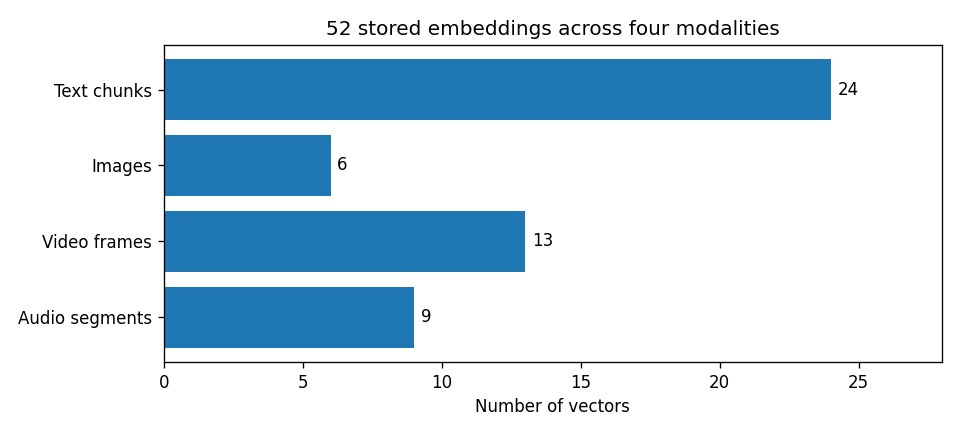

In [1]:
# Recorded counts from the completed Windows runs (not live Colab database data)
import matplotlib.pyplot as plt

labels = ["Text chunks", "Images", "Video frames", "Audio segments"]
counts = [24, 6, 13, 9]
fig, ax = plt.subplots(figsize=(8, 3.6))
bars = ax.barh(labels[::-1], counts[::-1])
ax.bar_label(bars, padding=4)
ax.set_xlabel("Number of vectors")
ax.set_title("52 stored embeddings across four modalities")
ax.set_xlim(0, 28)
plt.tight_layout()
plt.show()


---
## Optional live demo — show the real vector database inside Google Colab

The sections above are **ready to present without running any code**. If the professor wants to see a **working database** inside Colab, follow the next cells.

**You need four small files from your Windows computer**, all in:

`C:\Users\carlo\Downloads\Wildlife_Bird_Search\Wildlife_Bird_Search_Data_Collection_2026-11-12\data\processed`

1. `clip_embeddings.npz`
2. `clip_embeddings_manifest.csv`
3. `clap_audio_embeddings.npz`
4. `clap_audio_embeddings_manifest.csv`

The uploads are **not embedded** in the notebook. In Colab, run the following cell and select these four files in the file picker. This optional demo **rebuilds a temporary ChromaDB database using your original vectors**; it does not change the Windows project or regenerate CLIP/CLAP embeddings. Colab's temporary files can disappear when the session ends.


In [ ]:
# OPTIONAL: run only in Google Colab, then select the four files listed above.
from pathlib import Path

try:
    from google.colab import files
except ImportError:
    print("This upload cell is designed for Google Colab. On a local notebook, copy the four files into the notebook folder instead.")
else:
    print("Select the TWO .npz files and TWO _manifest.csv files from data/processed.")
    uploaded = files.upload()
    print("Uploaded:", ", ".join(sorted(uploaded)))


In [ ]:
# OPTIONAL: inspect the actual uploaded vectors and metadata (no model download)
from pathlib import Path
import csv
import numpy as np

INPUTS = [
    ("CLIP", "clip_embeddings.npz", "clip_embeddings_manifest.csv", 43),
    ("CLAP", "clap_audio_embeddings.npz", "clap_audio_embeddings_manifest.csv", 9),
]

PACKAGES = []
for name, vector_filename, csv_filename, expected in INPUTS:
    if not Path(vector_filename).is_file() or not Path(csv_filename).is_file():
        raise FileNotFoundError(f"Missing {vector_filename} or {csv_filename}. Upload all four files first.")
    with np.load(vector_filename, allow_pickle=False) as archive:
        vectors = np.asarray(archive["embeddings"], dtype=np.float32)
    with open(csv_filename, newline="", encoding="utf-8-sig") as handle:
        rows = list(csv.DictReader(handle))
    assert vectors.shape == (expected, 512), f"Unexpected shape for {name}: {vectors.shape}"
    assert len(rows) == expected, f"Unexpected manifest row count for {name}"
    ids = [r["item_id"] for r in rows]
    assert len(set(ids)) == len(ids), f"Duplicate IDs in {name}"
    norms = np.linalg.norm(vectors, axis=1, keepdims=True)
    assert np.all(np.isfinite(vectors)) and np.all(norms > 0), "Invalid vectors"
    vectors = vectors / norms
    PACKAGES.append((name, vectors, rows, ids))
    print(f"{name}: {vectors.shape[0]} actual embeddings, {vectors.shape[1]} dimensions")
print("All 52 real embeddings loaded correctly.")


### Build the ChromaDB collections from the uploaded files

Installing ChromaDB here is only required for this optional live Colab demonstration. We will use the **same 43+9 vectors already generated on Windows**, without downloading large AI models again.


In [ ]:
# OPTIONAL: install the vector database library in the Colab runtime
%pip -q install chromadb


In [ ]:
# OPTIONAL: build an HNSW index with cosine distance from the real uploaded vectors
import chromadb

client = chromadb.PersistentClient(path="/content/wildlife_colab_chroma")
COLLECTION_NAMES = {"CLIP": "wildlife_clip", "CLAP": "wildlife_audio"}
collections = {}

for model_name, vectors, rows, ids in PACKAGES:
    collection_name = COLLECTION_NAMES[model_name]
    collection = client.get_or_create_collection(
        name=collection_name,
        configuration={"hnsw": {"space": "cosine"}},
    )
    collection.upsert(
        ids=ids,
        embeddings=vectors.tolist(),
        metadatas=[{
            "species": row.get("species", ""),
            "modality": row.get("modality", ""),
            "file_path": row.get("file_path", ""),
            "source_file": row.get("source_file", ""),
            "start_seconds": row.get("start_seconds", ""),
            "end_seconds": row.get("end_seconds", ""),
            "embedding_space": "clip" if model_name == "CLIP" else "clap",
        } for row in rows],
        documents=[row.get("description", "") or row.get("species", "") for row in rows],
    )
    collections[model_name] = collection
    print(f"{collection_name}: {collection.count()} records")

print("HNSW indexes created using cosine distance. Total:", sum(c.count() for c in collections.values()))


### Test nearest-neighbor lookup (existing vector)

To prove the vector database can retrieve records, we query using an **existing stored vector**. This is a basic technical test, **not a real-world accuracy evaluation** and not yet a new user text/audio/image query.


In [ ]:
# OPTIONAL: test ANN lookup in each independent embedding space
for model_name, vectors, rows, ids in PACKAGES:
    result = collections[model_name].query(
        query_embeddings=[vectors[0].tolist()],
        n_results=3,
        include=["metadatas", "distances"],
    )
    print(f"\n{model_name} retrieval test:")
    for item_id, meta, distance in zip(
        result["ids"][0], result["metadatas"][0], result["distances"][0]
    ):
        print(f"- {item_id} | species={meta.get('species')} | cosine distance={distance:.4f}")


---
## Next steps (not completed yet)

1. Develop a search interface that accepts natural-language text, pictures and audio.
2. Query each model in its **compatible** space. For example, use CLIP text encoding for image/video retrieval and CLAP text encoding for bird-sound retrieval.
3. Combine the results into an understandable list, being careful not to treat CLIP and CLAP cosine scores as automatically comparable.
4. Test the quality of retrieval with new user queries and multiple bird species.
5. Prepare the final GitHub repository and PDF report.

**Checkpoint conclusion:** The requirements through **Database Insertion & Indexing** have been implemented and tested on the Windows project. This notebook is a presentation/report of that work, with an optional Colab demonstration using the original vectors.

**References:** [Wikimedia Commons](https://commons.wikimedia.org/), [ChromaDB documentation](https://docs.trychroma.com/), [CLIP](https://huggingface.co/openai/clip-vit-base-patch32), [CLAP](https://huggingface.co/laion/clap-htsat-unfused).
